# Kidney Perturbation Analysis

- Creator: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 28.01.2026
- Date of Last Modification: 01.02.2026 (by Sebastian Birk; sb75@sanger.ac.uk)

# 1. Setup

## 1.1 Load Libraries

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import pickle

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
import torch
from datasets import load_from_disk

#from app.count_decoder import apply_count_decoder
from app.infer import embed_dataset, harmonize_tokenize_embed_pipeline, perturb_dataset
from nichejepa.preprocessors import construct_neighbor_graph

/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


## 1.2 Define Config/Params

In [3]:
# Define paths
model_folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/11012026_190057_836' # cross-tissue model
#model_folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/01112025_081731_614' # benchmarking model
gene_ensembl_map_file_path = '/nfs/team361/sb75/DATASETS/genes/homo_sapiens_gene_name_to_ensembl_id_dict.pkl'
kidney_perturbation_folder_path = '/nfs/team361/sb75/DATASETS/gold/cell-graph-tokenizer/kidney_perturbation'
cache_directory_path = f'{kidney_perturbation_folder_path}/cache'
results_directory_path = f'{kidney_perturbation_folder_path}/results'
tokenized_data_directory_path = f'{kidney_perturbation_folder_path}/tokenized_data'

In [4]:
niche_key = "NEMO_neighborhood_annotation"
batch_key = 'Study_slice_id'

emb_layer = None
batch_size = 128
pin_memory = False
num_workers = 12
agg_excluded_tokens = None
top_k = None

## 1.3 Run Notebook Setup

In [5]:
torch.set_printoptions(threshold=float('inf'))

In [6]:
os.makedirs(tokenized_data_directory_path, exist_ok=True)
os.makedirs(f'{results_directory_path}/figures', exist_ok=True)

In [7]:
plt.rcParams['font.size'] = 5
plt.rcParams['text.usetex'] = False
plt.rcParams['svg.fonttype'] = 'none'

In [8]:
# Improve reproducibility of UMAP and Leiden
os.environ['NUMBA_CPU_NAME'] = 'generic'

In [9]:
sc.settings.figdir = f'{results_directory_path}/figures'

sc.settings.set_figure_params(
    dpi=300,
    dpi_save=300,
    figsize=(6, 4),
    facecolor='white',
    fontsize=10
)

# 2. Analysis

## 2.1 Load Data

In [ ]:
# Load original raw data
adata = sc.read_h5ad(
    "/nfs/team361/dj17/NEMO_DJ/KidneyToxicity/NEMO_UpdatedTokenisationandEmbedding_November22nd25/Labeltransfer/forshare/nemokidneyxeniumatlas_annotated.h5ad")
adata

In [ ]:
# Check columns
adata.obs.head(1)

In [ ]:
# List samples
# CV*** -> pre-treatment
# DI*** -> post-treatment
adata.obs[['Study_slice_id', 'Data_source']].drop_duplicates()

In [ ]:
# Compute sample-wise neighbor graph, concatenate, and store in adata.obsp['spatial_connectivities']
adata = construct_neighbor_graph(
    adata,
    n_neighs=10,
    radius=None,
    delaunay=False,
    include_self_loop=False,
    compute_neighbor_counts=False,
    batch_key=batch_key
)

# Compute raw neighborhood counts
adata.layers['counts_neighborhood'] = (
    adata.obsp['spatial_connectivities'].T @ adata.layers['counts'])
print(adata.layers['counts_neighborhood'][:30].toarray())
adata.layers['counts_neighborhood'] += adata.layers['counts'] # add counts from the index cell
print(adata.layers['counts_neighborhood'][:30].toarray())

# Compute lognorm neighborhood counts (performing same normalization as on raw counts)
adata.X = adata.layers["counts_neighborhood"].copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.layers["lognorm_neighborhood"] = adata.X.copy()
adata.X = adata.layers["lognorm"].copy()

In [ ]:
# Validate that everything is ok
print(adata.obsp['spatial_connectivities'].sum(1))
n = 30
print(adata.layers['counts_neighborhood'][:30].toarray())
print(adata.layers['lognorm_neighborhood'][:30].toarray())
print(adata.layers['counts'][:30].toarray())
print(adata.layers['lognorm'][:30].toarray())
print(adata.X[:30].toarray())

In [ ]:
# Add ensembl IDs to AnnData object
with open(gene_ensembl_map_file_path, "rb") as f:
    gene_ensembl_map_dict = pickle.load(f)

gene_names = [gene_name for gene_name in adata.var_names.tolist()]
adata.var.index = gene_names

harmonized_gene_names = []
matching_ensembl_ids = []
for gene_name in gene_names:
    if gene_name in gene_ensembl_map_dict.keys():
        harmonized_gene_names.append(gene_name)
        matching_ensembl_ids.append(gene_ensembl_map_dict[gene_name])

adata.var['ensembl_id'] = matching_ensembl_ids
adata.var

In [ ]:
# Write AnnData to disk
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_annotated_processed.h5ad")

In [ ]:
# Load processed AnnData
adata = sc.read_h5ad(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_annotated_processed.h5ad")

## 2.2 Compute Differential Genes Between Pre- and Post-treatment Conditions

Check https://docs.google.com/spreadsheets/d/1i6p3QRTE5Lh32AejWE6Xg2Sye6p3yP7vDdrCMDbLj_I/edit?gid=1921994032#gid=1921994032 for perturbation cases to be tested.

### 2.2.1 Perturbation Case 1

In [ ]:
sid = adata.obs["Study_slice_id"].astype(str)

adata.obs["DI12_vs_CV"] = np.nan
adata.obs.loc[sid.eq("DI12-KID-0-FT-4"), "DI12_vs_CV"] = "DI12"
adata.obs.loc[sid.str.startswith("CV"), "DI12_vs_CV"] = "CV"

adata.obs["DI12_vs_CV"] = adata.obs["DI12_vs_CV"].astype("category")
adata.obs["DI12_vs_CV"].value_counts(dropna=False)

In [ ]:
# Compute differential genes for cell counts (across all cells -> global)
sc.tl.rank_genes_groups(
    adata,
    groupby="DI12_vs_CV",
    groups=["DI12"],
    reference="CV",
    method="wilcoxon",
    pts=True,
    use_raw=False,
    key_added="rank_genes_groups_case1_global_pre_post_cell_counts",
)

# Retrieve differential genes for cell counts
n = 50
diff_genes_df = sc.get.rank_genes_groups_df(adata, group="DI12", key="rank_genes_groups_case1_global_pre_post_cell_counts")
diff_genes_df_top = diff_genes_df.head(n)
diff_genes_df_top[["names", "logfoldchanges", "pvals_adj", "scores"]]
display(diff_genes_df_top)
diff_genes_df_top.to_csv(f"{results_directory_path}/nemokidneyxeniumatlas_top_{n}_diff_genes_case1_global_pre_post_cell_counts.csv")

In [ ]:
# Compute differential genes for cell counts (across each niche)
# Loop over niches and run DE within each
min_cells_per_group = 20

summary_rows = []

# Get categories (handles categorical + non-categorical)
cats = adata.obs[niche_key].astype("category").cat.categories

for cat in cats:
    # Cells in this niche AND in either DI12 or CV
    mask = (adata.obs[niche_key] == cat) & (adata.obs["DI12_vs_CV"].isin(["DI12", "CV"]))
    n_total = int(mask.sum())
    if n_total == 0:
        summary_rows.append({"niche": str(cat), "status": "skipped (no DI12/CV cells)", "n_DI12": 0, "n_CV": 0})
        continue

    sub = adata[mask].copy() # copy so we can compute safely without view warnings

    counts = sub.obs["DI12_vs_CV"].value_counts()
    n_di12 = int(counts.get("DI12", 0))
    n_cv   = int(counts.get("CV", 0))

    if n_di12 < min_cells_per_group or n_cv < min_cells_per_group:
        summary_rows.append({
            "niche": str(cat),
            "status": f"skipped (too few cells; min={min_cells_per_group})",
            "n_DI12": n_di12,
            "n_CV": n_cv
        })
        continue

    key = f"rank_genes_groups_case1_niche={cat}_pre_post_cell_counts"

    sc.tl.rank_genes_groups(
        sub,
        groupby="DI12_vs_CV",
        groups=["DI12"],
        reference="CV",
        method="wilcoxon",
        pts=True,
        use_raw=False,
        key_added=key,
    )

    # Retrieve differential genes for cell counts
    n = 50
    diff_genes_df = sc.get.rank_genes_groups_df(sub, group="DI12", key=key)
    diff_genes_df_top = diff_genes_df.head(n)
    diff_genes_df_top[["names", "logfoldchanges", "pvals_adj", "scores"]]
    display(diff_genes_df_top)
    diff_genes_df_top.to_csv(f"{results_directory_path}/nemokidneyxeniumatlas_top_{n}_diff_genes_case1_niche_{cat}_pre_post_cell_counts.csv")
    
    # Store results on the original adata
    adata.uns[key] = sub.uns[key]

    summary_rows.append({
        "niche": str(cat),
        "status": "ok",
        "n_DI12": n_di12,
        "n_CV": n_cv,
        "uns_key": key
    })

# Store a summary table on the AnnData for bookkeeping
adata.uns["DE_case1_pre_post_cell_counts_summary_by_niche"] = pd.DataFrame(summary_rows)
adata.uns["DE_case1_pre_post_cell_counts_summary_by_niche"]

In [ ]:
# Compute differential genes for neighborhood counts
adata.X = adata.layers['lognorm_neighborhood'].copy()
sc.tl.rank_genes_groups(
    adata,
    groupby="DI12_vs_CV",
    groups=["DI12"],
    reference="CV",
    method="wilcoxon",
    pts=True,
    use_raw=False,
    key_added="rank_genes_groups_case1_global_pre_post_neighborhood_counts",
)

# Retrieve differential genes for neighborhood counts
n = 50
diff_genes_df = sc.get.rank_genes_groups_df(adata, group="DI12", key="rank_genes_groups_case1_global_pre_post_neighborhood_counts")
diff_genes_df_top = diff_genes_df.head(n)
diff_genes_df_top[["names", "logfoldchanges", "pvals_adj", "scores"]]
display(diff_genes_df_top)
diff_genes_df_top.to_csv(f"{results_directory_path}/nemokidneyxeniumatlas_top_{n}_diff_genes_case1_pre_post_neighborhood_counts.csv")

In [ ]:
# Compute differential genes for neighborhood counts (across each niche)
# Loop over niches and run DE within each
min_cells_per_group = 20

summary_rows = []

# Get categories (handles categorical + non-categorical)
cats = adata.obs[niche_key].astype("category").cat.categories

for cat in cats:
    # Cells in this niche AND in either DI12 or CV
    mask = (adata.obs[niche_key] == cat) & (adata.obs["DI12_vs_CV"].isin(["DI12", "CV"]))
    n_total = int(mask.sum())
    if n_total == 0:
        summary_rows.append({"niche": str(cat), "status": "skipped (no DI12/CV cells)", "n_DI12": 0, "n_CV": 0})
        continue

    sub = adata[mask].copy() # copy so we can compute safely without view warnings

    counts = sub.obs["DI12_vs_CV"].value_counts()
    n_di12 = int(counts.get("DI12", 0))
    n_cv   = int(counts.get("CV", 0))

    if n_di12 < min_cells_per_group or n_cv < min_cells_per_group:
        summary_rows.append({
            "niche": str(cat),
            "status": f"skipped (too few cells; min={min_cells_per_group})",
            "n_DI12": n_di12,
            "n_CV": n_cv
        })
        continue

    key = f"rank_genes_groups_case1_niche={cat}_pre_post_neighborhood_counts"

    sc.tl.rank_genes_groups(
        sub,
        groupby="DI12_vs_CV",
        groups=["DI12"],
        reference="CV",
        method="wilcoxon",
        pts=True,
        use_raw=False,
        key_added=key,
    )

    # Retrieve differential genes for cell counts
    n = 50
    diff_genes_df = sc.get.rank_genes_groups_df(sub, group="DI12", key=key)
    diff_genes_df_top = diff_genes_df.head(n)
    diff_genes_df_top[["names", "logfoldchanges", "pvals_adj", "scores"]]
    display(diff_genes_df_top)
    diff_genes_df_top.to_csv(f"{results_directory_path}/nemokidneyxeniumatlas_top_{n}_diff_genes_case1_niche_{cat}_pre_post_neighborhood_counts.csv")
    
    # Store results on the original adata
    adata.uns[key] = sub.uns[key]

    summary_rows.append({
        "niche": str(cat),
        "status": "ok",
        "n_DI12": n_di12,
        "n_CV": n_cv,
        "uns_key": key
    })

# Store a summary table on the AnnData for bookkeeping
adata.uns["DE_case1_pre_post_neighborhood_counts_summary_by_niche"] = pd.DataFrame(summary_rows)
adata.uns["DE_case1_pre_post_neighborhood_counts_summary_by_niche"]

In [ ]:
adata.X = adata.layers['lognorm'].copy()

In [ ]:
# Write AnnData to disk
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_annotated_processed.h5ad")

### 2.2.2 Perturbation Case 2

In [ ]:
# Load processed AnnData
adata = sc.read_h5ad(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_annotated_processed.h5ad")

In [ ]:
sid = adata.obs["Study_slice_id"].astype(str)

adata.obs["DI10_vs_CV"] = np.nan
adata.obs.loc[sid.eq("DI10-KID-0-FT-5"), "DI10_vs_CV"] = "DI10"
adata.obs.loc[sid.str.startswith("CV"), "DI10_vs_CV"] = "CV"

adata.obs["DI10_vs_CV"] = adata.obs["DI10_vs_CV"].astype("category")
adata.obs["DI10_vs_CV"].value_counts(dropna=False)

In [ ]:
# Compute differential genes for cell counts (across all cells -> global)
sc.tl.rank_genes_groups(
    adata,
    groupby="DI10_vs_CV",
    groups=["DI10"],
    reference="CV",
    method="wilcoxon",
    pts=True,
    use_raw=False,
    key_added="rank_genes_groups_case2_global_pre_post_cell_counts",
)

# Retrieve differential genes for cell counts
n = 50
diff_genes_df = sc.get.rank_genes_groups_df(adata, group="DI10", key="rank_genes_groups_case2_global_pre_post_cell_counts")
diff_genes_df_top = diff_genes_df.head(n)
diff_genes_df_top[["names", "logfoldchanges", "pvals_adj", "scores"]]
display(diff_genes_df_top)
diff_genes_df_top.to_csv(f"{results_directory_path}/nemokidneyxeniumatlas_top_{n}_diff_genes_case2_global_pre_post_cell_counts.csv")

In [ ]:
# Compute differential genes for cell counts (across each niche)
# Loop over niches and run DE within each
min_cells_per_group = 20

summary_rows = []

# Get categories (handles categorical + non-categorical)
cats = adata.obs[niche_key].astype("category").cat.categories

for cat in cats:
    # Cells in this niche AND in either DI10 or CV
    mask = (adata.obs[niche_key] == cat) & (adata.obs["DI10_vs_CV"].isin(["DI10", "CV"]))
    n_total = int(mask.sum())
    if n_total == 0:
        summary_rows.append({"niche": str(cat), "status": "skipped (no DI10/CV cells)", "n_DI10": 0, "n_CV": 0})
        continue

    sub = adata[mask].copy() # copy so we can compute safely without view warnings

    counts = sub.obs["DI10_vs_CV"].value_counts()
    n_di10 = int(counts.get("DI10", 0))
    n_cv   = int(counts.get("CV", 0))

    if n_di10 < min_cells_per_group or n_cv < min_cells_per_group:
        summary_rows.append({
            "niche": str(cat),
            "status": f"skipped (too few cells; min={min_cells_per_group})",
            "n_DI10": n_di10,
            "n_CV": n_cv
        })
        continue

    key = f"rank_genes_groups_case2_niche={cat}_pre_post_cell_counts"

    sc.tl.rank_genes_groups(
        sub,
        groupby="DI10_vs_CV",
        groups=["DI10"],
        reference="CV",
        method="wilcoxon",
        pts=True,
        use_raw=False,
        key_added=key,
    )

    # Retrieve differential genes for cell counts
    n = 50
    diff_genes_df = sc.get.rank_genes_groups_df(sub, group="DI10", key=key)
    diff_genes_df_top = diff_genes_df.head(n)
    diff_genes_df_top[["names", "logfoldchanges", "pvals_adj", "scores"]]
    display(diff_genes_df_top)
    diff_genes_df_top.to_csv(f"{results_directory_path}/nemokidneyxeniumatlas_top_{n}_diff_genes_case2_niche_{cat}_pre_post_cell_counts.csv")
    
    # Store results on the original adata
    adata.uns[key] = sub.uns[key]

    summary_rows.append({
        "niche": str(cat),
        "status": "ok",
        "n_DI10": n_di10,
        "n_CV": n_cv,
        "uns_key": key
    })

# Store a summary table on the AnnData for bookkeeping
adata.uns["DE_case2_pre_post_cell_counts_summary_by_niche"] = pd.DataFrame(summary_rows)
adata.uns["DE_case2_pre_post_cell_counts_summary_by_niche"]

In [ ]:
# Compute differential genes for neighborhood counts (across all cells -> global)
adata.X = adata.layers['lognorm_neighborhood'].copy()
sc.tl.rank_genes_groups(
    adata,
    groupby="DI10_vs_CV",
    groups=["DI10"],
    reference="CV",
    method="wilcoxon",
    pts=True,
    use_raw=False,
    key_added="rank_genes_groups_case2_global_pre_post_neighborhood_counts",
)

# Retrieve differential genes for neighborhood counts
n = 50
diff_genes_df = sc.get.rank_genes_groups_df(adata, group="DI10", key="rank_genes_groups_case2_global_pre_post_neighborhood_counts")
diff_genes_df_top = diff_genes_df.head(n)
diff_genes_df_top[["names", "logfoldchanges", "pvals_adj", "scores"]]
display(diff_genes_df_top)
diff_genes_df_top.to_csv(f"{results_directory_path}/nemokidneyxeniumatlas_top_{n}_diff_genes_case2_global_pre_post_neighborhood_counts.csv")

In [ ]:
# Compute differential genes for neighborhood counts (across each niche)
# Loop over niches and run DE within each
min_cells_per_group = 20

summary_rows = []

# Get categories (handles categorical + non-categorical)
cats = adata.obs[niche_key].astype("category").cat.categories

for cat in cats:
    # Cells in this niche AND in either DI10 or CV
    mask = (adata.obs[niche_key] == cat) & (adata.obs["DI10_vs_CV"].isin(["DI10", "CV"]))
    n_total = int(mask.sum())
    if n_total == 0:
        summary_rows.append({"niche": str(cat), "status": "skipped (no DI10/CV cells)", "n_DI10": 0, "n_CV": 0})
        continue

    sub = adata[mask].copy() # copy so we can compute safely without view warnings

    counts = sub.obs["DI10_vs_CV"].value_counts()
    n_di10 = int(counts.get("DI10", 0))
    n_cv   = int(counts.get("CV", 0))

    if n_di10 < min_cells_per_group or n_cv < min_cells_per_group:
        summary_rows.append({
            "niche": str(cat),
            "status": f"skipped (too few cells; min={min_cells_per_group})",
            "n_DI10": n_di10,
            "n_CV": n_cv
        })
        continue

    key = f"rank_genes_groups_case2_niche={cat}_pre_post_neighborhood_counts"

    sc.tl.rank_genes_groups(
        sub,
        groupby="DI10_vs_CV",
        groups=["DI10"],
        reference="CV",
        method="wilcoxon",
        pts=True,
        use_raw=False,
        key_added=key,
    )

    # Retrieve differential genes for neighborhood counts
    n = 50
    diff_genes_df = sc.get.rank_genes_groups_df(sub, group="DI10", key=key)
    diff_genes_df_top = diff_genes_df.head(n)
    diff_genes_df_top[["names", "logfoldchanges", "pvals_adj", "scores"]]
    display(diff_genes_df_top)
    diff_genes_df_top.to_csv(f"{results_directory_path}/nemokidneyxeniumatlas_top_{n}_diff_genes_case2_niche_{cat}_pre_post_neighborhood_counts.csv")
    
    # Store results on the original adata
    adata.uns[key] = sub.uns[key]

    summary_rows.append({
        "niche": str(cat),
        "status": "ok",
        "n_DI10": n_di10,
        "n_CV": n_cv,
        "uns_key": key
    })

# Store a summary table on the AnnData for bookkeeping
adata.uns["DE_case2_pre_post_neighborhood_counts_summary_by_niche"] = pd.DataFrame(summary_rows)
adata.uns["DE_case2_pre_post_neighborhood_counts_summary_by_niche"]

In [ ]:
adata.X = adata.layers['lognorm'].copy()

In [ ]:
# Write AnnData to disk
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_annotated_processed.h5ad")

### 2.2.3 Perturbation Case 3

Same as in perturbation case 2.

## 2.3 Tokenize Data & Retrieve Embeddings

In [10]:
adata = sc.read_h5ad(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_annotated_processed.h5ad")

In [11]:
# Check that indices are unique
assert len(np.unique(list(adata.obs_names))) == len(adata)

In [12]:
# Overwrite cell IDs with unique indices
adata.obs['cell_id'] = adata.obs_names

In [13]:
# Make sure raw counts are stored in adata.X
adata.X = adata.layers['counts'].copy()

In [14]:
adata = harmonize_tokenize_embed_pipeline(
    adata=adata,
    sample_key=batch_key,
    model_folder_path=model_folder_path,
    cache_directory_path=cache_directory_path,
    gene_perturb_df=None,               
    nproc=4,
    processing_mode='parallel',
    save_dataset_path=f"{tokenized_data_directory_path}/nemokidneyxeniumatlas",
    num_shards=32,
    emb_layer=None,
    agg_excluded_tokens=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    use_generator=True,
    add_neigh_cell_ids=True,
    min_cells_per_gene=0,
    ignore_spc_tokens=True)

Start processing sample: CV9-KID-0-FT-5-S4...
Harmonizing sample CV9-KID-0-FT-5-S4...
STEP 1: DATA VALIDATION...
Checking that adata.X contains raw counts...
STEP 2: ADDING ENSEMBL IDS...
Adding ensembl IDs from gene_mapping_dict with file path `/lustre/scratch126/cellgen/lotfollahi/DATASETS/genes/homo_sapiens_gene_name_to_ensembl_id_dict.pkl`...


/nfs/team361/sb75/nichejepa/src/app/infer.py:771: ImplicitModificationWarning: Trying to modify index of attribute `.var` of view, initializing view as actual.
  adata.var.index = adata_gene_names


Number of genes with matching ensembl IDs: 4949.
Number of genes skipped due to non-matching ensembl IDs: 0.
Filtering genes that have not occurred enough during pretraining...
Number of genes skipped due to not enough pretraining occurrences: 0.
STEP 3: BASIC QUALITY CONTROL...
Filtering cells with less than 10 genes.
Filtering genes expressed in less than 0 cells.


INFO:nichejepa.tokenizers.cell_tokenizers:Loading token dictionary from /nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/11012026_190057_836/token_dictionary.pkl.


STEP 4: ADDING SPECIAL VALUES...
Harmonized sample CV9-KID-0-FT-5-S4.
Tokenizing sample CV9-KID-0-FT-5-S4...
STEP 1: LOADING CONFIG...
STEP 2: TOKENIZING ANNDATA OBJECT...
Filtering cells...
No 'filter_pass' column in 'adata.obs'; returning full adata.
Computing spatial neighborhood...
Normalizing gene expression counts...


/nfs/team361/sb75/nichejepa/src/nichejepa/tokenizers/cell_tokenizers.py:663: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coding_miRNA_ids = adata.var['ensembl_id'][coding_miRNA_idx]


... (120 outputs left out)

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr']


0it [00:00, ?it/s]/nfs/team361/sb75/nichejepa/src/app/infer.py:1119: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
11859it [7:48:39,  2.37s/it]


Embedded tokenized data.


/nfs/team361/sb75/nichejepa/src/app/infer.py:1566: ImplicitModificationWarning: Setting element `.obsm['cell_emb']` of view, initializing view as actual.
  adata.obsm[key] = values


In [15]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

## 2.4 Perform Perturbations

In [10]:
adata = sc.read_h5ad(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

In [11]:
dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas")

In [12]:
# Filter dataset for perturbation
pre_treatment_cell_ids = adata[adata.obs['Data_source'] == 'DIAMOND'].obs['cell_id']
pre_treatment_cell_ids_set = set(pre_treatment_cell_ids)
filtered_dataset = dataset.filter(
    lambda x: x["cell_id"] in pre_treatment_cell_ids_set
)
filtered_dataset

Dataset({
    features: ['rel_x_coord', 'rel_y_coord', 'cell_id', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'n_nonzero_tokens'],
    num_rows: 1081189
})

In [13]:
filtered_adata = adata[adata.obs_names.isin(pre_treatment_cell_ids)]
filtered_adata

View of AnnData object with n_obs × n_vars = 1081189 × 4949
    obs: 'cell_id', 'Study_slice_id', 'NEMO_K_SLICE_ID', 'NEMO_K_PATIENT_ID', 'Corpus_ID', 'Study_patient_id', 'Data_source', 'Platform', 'Tissue_subregion', 'Status', 'Diagnosis', 'Type', 'Age', 'Age_grouping', 'Sex', 'eGFR', 'eGFR_group', 'BMI', 'Obesity_status', 'eGFR baseline', 'eGFR change', 'RCC_Treatment', 'batch', 'NEMO_cell_label', 'NEMO_neighborhood_label', 'tech', 'scANVI_pred', 'scANVI_confidence', 'slice', 'NEMO_neighborhood_annotation', 'leiden', 'highlight_neigh', 'DI12_vs_CV', 'DI10_vs_CV'
    var: 'ensembl_id'
    uns: 'DE_case1_pre_post_cell_counts_summary_by_niche', 'DE_case1_pre_post_neighborhood_counts_summary_by_niche', 'DE_case2_pre_post_cell_counts_summary_by_niche', 'DE_case2_pre_post_neighborhood_counts_summary_by_niche', 'Data_source_colors', 'NEMO_K_PATIENT_ID_colors', 'NEMO_cell_label_colors', 'NEMO_neighborhood_annotation_colors', 'NEMO_neighborhood_label_colors', 'Obesity_status_colors', 'Sex_col

### 2.4.1 Perturbation Case 1

Knockout Perturbation:
- Cell & Neighborhood
    - CTLA4 (ENSG00000163599)
    - PDCD1 (ENSG00000188389)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with DI12-KID-0-FT-4

In [30]:
# Retrieve gene ensembl IDs
print(filtered_adata.var[filtered_adata.var_names == 'PDCD1'])
print(filtered_adata.var[filtered_adata.var_names == 'CTLA4'])

            ensembl_id
PDCD1  ENSG00000188389
            ensembl_id
CTLA4  ENSG00000163599


In [31]:
# Define perturbation
perturbed_cell_id = ['all', 'all', 'all', 'all']
perturbed_ensembl_id = ['ENSG00000163599', 'ENSG00000163599', 'ENSG00000188389', 'ENSG00000188389'] # ['all'] * len(perturbed_cell_id)
perturbation_target = ['cell', 'neighborhood', 'cell', 'neighborhood'] # ['neighborhood'] * len(perturbed_cell_id)
perturbation_type = ['knockout', 'knockout', 'knockout', 'knockout'] # ['knockout'] * len(perturbed_cell_id)
foldchange = [np.nan, np.nan, np.nan, np.nan] # [np.nan] * len(perturbed_cell_id)

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})
perturb_df

,perturbed_cell_id,perturbed_ensembl_id,perturbation_target,perturbation_type,foldchange
0,all,ENSG00000163599,cell,knockout,NaN
1,all,ENSG00000163599,neighborhood,knockout,NaN
2,all,ENSG00000188389,cell,knockout,NaN
3,all,ENSG00000188389,neighborhood,knockout,NaN


In [32]:
# Run perturbation
perturbed_dataset = perturb_dataset(
    dataset=filtered_dataset,
    perturb_df=perturb_df,
    nproc=1,
    model_folder_path=model_folder_path,
    return_only_perturbed_cells=True)
perturbed_dataset

Applying perturbations using dataframe:
  perturbed_cell_id perturbed_ensembl_id perturbation_target  \
0               all      ENSG00000163599                cell   
1               all      ENSG00000163599        neighborhood   
2               all      ENSG00000188389                cell   
3               all      ENSG00000188389        neighborhood   

  perturbation_type  foldchange perturbed_gene_token  
0          knockout         NaN                10985  
1          knockout         NaN                10985  
2          knockout         NaN                15995  
3          knockout         NaN                15995  


Map:   3%|▎         | 35000/1081189 [00:12<06:24, 2721.90 examples/s]


KeyboardInterrupt: 

In [ ]:
pert_idx_count_dict = {}

for idx, row in perturb_df.iterrows():
    pert_idx_count_dict[f"idx_{idx}"] = sum(f.item() for f in perturbed_dataset[f'pert_flag_idx_{idx}'])
    print(f"{pert_idx_count_dict[f'idx_{idx}']}/{len(filtered_dataset)} cells are impacted by perturbation {idx}.")

In [ ]:
n_cells = filtered_adata.n_obs

def cells_expressing(gene, pert_target, threshold=0):
    j = filtered_adata.var_names.get_loc(gene)  # column index for gene
    if pert_target == 'cell':
        col = filtered_adata.layers['counts'][:, j]
    elif pert_target == 'neighborhood':
        col = filtered_adata.layers['counts_neighborhood'][:, j]
    if sp.issparse(col):
        # sparse: only stored values are non-zero
        return int((col > threshold).sum())
    else:
        return int(np.sum(col > threshold))

for idx, row in perturb_df.iterrows():
    ensembl_id = row["perturbed_ensembl_id"]
    pert_target = row["perturbation_target"]
    gene = filtered_adata.var[filtered_adata.var['ensembl_id'] == ensembl_id].index[0]
    if gene not in filtered_adata.var_names:
        print(f"{gene}: not found in filtered_adata.var_names")
        continue

    c = cells_expressing(gene, pert_target, threshold=0)
    print(f"{c}/{n_cells} express {gene} for perturbation {idx}.")

In [ ]:
perturbed_dataset.save_to_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case1")

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case1")

In [39]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_tokens=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

STEP 1: LOADING CONFIG...
STEP 2: GENERATING EMBEDDINGS...


INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (seg_embed): Embedding(13, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affi

Special token pad ratio 0.0


/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:626: UserWarning: This DataLoader will create 12 worker processes in total. Our suggested max number of worker in current system is 6, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
INFO:root:Dataloader and -sampler created.
INFO:root:Loaded pretrained target encoder from epoch 1 with msg: <All keys matched successfully>.
INFO:root:Finished loading checkpoint with read path: /nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/11012026_190057_836/model_checkpoint.pt.


['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr']


0it [00:00, ?it/s]/nfs/team361/sb75/nichejepa/src/app/infer.py:1126: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
259it [08:50,  2.05s/it]


In [40]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case1'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case1"][ai],
            perturbed_output_embed[emb_key][pi],
        )

In [41]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

### 2.4.2 Perturbation Case 2

Knockout Perturbation:
- Cell & Neighborhood
    - CTLA4 (ENSG00000163599)
    - PDCD1 (ENSG00000188389)
    - KDR (ENSG00000128052)
    - FLT4 (ENSG00000037280)
    - PDGFRA (ENSG00000134853)
    - PDGFRB (ENSG00000113721)
    - KIT (ENSG00000157404)
    - CSF3R (ENSG00000119535)
    - FLT3 (ENSG00000122025)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with DI10-KID-0-FT-5

In [14]:
# Retrieve gene ensembl IDs
print(filtered_adata.var[filtered_adata.var_names == 'CTLA4'])
print(filtered_adata.var[filtered_adata.var_names == 'PDCD1'])
print(filtered_adata.var[filtered_adata.var_names == 'KDR'])
print(filtered_adata.var[filtered_adata.var_names == 'FLT4'])
print(filtered_adata.var[filtered_adata.var_names == 'PDGFRA'])
print(filtered_adata.var[filtered_adata.var_names == 'PDGFRB'])
print(filtered_adata.var[filtered_adata.var_names == 'KIT'])
print(filtered_adata.var[filtered_adata.var_names == 'CSF3R'])
print(filtered_adata.var[filtered_adata.var_names == 'FLT3'])

            ensembl_id
CTLA4  ENSG00000163599
            ensembl_id
PDCD1  ENSG00000188389
          ensembl_id
KDR  ENSG00000128052
           ensembl_id
FLT4  ENSG00000037280
             ensembl_id
PDGFRA  ENSG00000134853
             ensembl_id
PDGFRB  ENSG00000113721
          ensembl_id
KIT  ENSG00000157404
            ensembl_id
CSF3R  ENSG00000119535
           ensembl_id
FLT3  ENSG00000122025


In [15]:
# Define perturbation
perturbed_cell_id = ['all'] * 18
perturbed_ensembl_id = [
    'ENSG00000163599',
    'ENSG00000163599',
    'ENSG00000188389',
    'ENSG00000188389',
    'ENSG00000128052',
    'ENSG00000128052',
    'ENSG00000037280',
    'ENSG00000037280',
    'ENSG00000134853',
    'ENSG00000134853',
    'ENSG00000113721',
    'ENSG00000113721',
    'ENSG00000157404',
    'ENSG00000157404',
    'ENSG00000119535',
    'ENSG00000119535',
    'ENSG00000122025',
    'ENSG00000122025',]
perturbation_target = ['cell', 'neighborhood'] * 9
perturbation_type = ['knockout'] * 18
foldchange = [np.nan] * 18

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})
perturb_df

,perturbed_cell_id,perturbed_ensembl_id,perturbation_target,perturbation_type,foldchange
0,all,ENSG00000163599,cell,knockout,NaN
1,all,ENSG00000163599,neighborhood,knockout,NaN
2,all,ENSG00000188389,cell,knockout,NaN
3,all,ENSG00000188389,neighborhood,knockout,NaN
4,all,ENSG00000128052,cell,knockout,NaN
5,all,ENSG00000128052,neighborhood,knockout,NaN
6,all,ENSG00000037280,cell,knockout,NaN
7,all,ENSG00000037280,neighborhood,knockout,NaN
8,all,ENSG00000134853,cell,knockout,NaN
9,all,ENSG00000134853,neighborhood,knockout,NaN


In [16]:
# Run perturbation
perturbed_dataset = perturb_dataset(
    dataset=filtered_dataset,
    perturb_df=perturb_df,
    nproc=1,
    model_folder_path=model_folder_path,
    return_only_perturbed_cells=True)
perturbed_dataset

Applying perturbations using dataframe:
   perturbed_cell_id perturbed_ensembl_id perturbation_target  \
0                all      ENSG00000163599                cell   
1                all      ENSG00000163599        neighborhood   
2                all      ENSG00000188389                cell   
3                all      ENSG00000188389        neighborhood   
4                all      ENSG00000128052                cell   
5                all      ENSG00000128052        neighborhood   
6                all      ENSG00000037280                cell   
7                all      ENSG00000037280        neighborhood   
8                all      ENSG00000134853                cell   
9                all      ENSG00000134853        neighborhood   
10               all      ENSG00000113721                cell   
11               all      ENSG00000113721        neighborhood   
12               all      ENSG00000157404                cell   
13               all      ENSG00000157404        n

Map: 2162378 examples [07:17, 2471.20 examples/s]                                                      
Filter: 2162378 examples [02:12, 8187.66 examples/s]                                                   


Dataset({
    features: ['rel_x_coord', 'rel_y_coord', 'cell_id', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'n_nonzero_tokens', 'pert_flag_idx_0', 'pert_flag_idx_1', 'pert_flag_idx_2', 'pert_flag_idx_3', 'pert_flag_idx_4', 'pert_flag_idx_5', 'pert_flag_idx_6', 'pert_flag_idx_7', 'pert_flag_idx_8', 'pert_flag_idx_9', 'pert_flag_idx_10', 'pert_flag_idx_11', 'pert_flag_idx_12', 'pert_flag_idx_13', 'pert_flag_idx_14', 'pert_flag_idx_15', 'pert_flag_idx_16', 'pert_flag_idx_17'],
    num_rows: 742831
})

In [45]:
pert_idx_count_dict = {}

for idx, row in perturb_df.iterrows():
    pert_idx_count_dict[f"idx_{idx}"] = sum(f.item() for f in perturbed_dataset[f'pert_flag_idx_{idx}'])
    print(f"{pert_idx_count_dict[f'idx_{idx}']}/{len(filtered_dataset)} cells are impacted by perturbation {idx}.")

2493/1081189 cells are impacted by perturbation 0.
22237/1081189 cells are impacted by perturbation 1.
1009/1081189 cells are impacted by perturbation 2.
9796/1081189 cells are impacted by perturbation 3.
35802/1081189 cells are impacted by perturbation 4.
236227/1081189 cells are impacted by perturbation 5.
52825/1081189 cells are impacted by perturbation 6.
315348/1081189 cells are impacted by perturbation 7.
60505/1081189 cells are impacted by perturbation 8.
355480/1081189 cells are impacted by perturbation 9.
94060/1081189 cells are impacted by perturbation 10.
479290/1081189 cells are impacted by perturbation 11.
9412/1081189 cells are impacted by perturbation 12.
82338/1081189 cells are impacted by perturbation 13.
2725/1081189 cells are impacted by perturbation 14.
26328/1081189 cells are impacted by perturbation 15.
681/1081189 cells are impacted by perturbation 16.
6571/1081189 cells are impacted by perturbation 17.


In [46]:
n_cells = filtered_adata.n_obs

def cells_expressing(gene, pert_target, threshold=0):
    j = filtered_adata.var_names.get_loc(gene)  # column index for gene
    if pert_target == 'cell':
        col = filtered_adata.layers['counts'][:, j]
    elif pert_target == 'neighborhood':
        col = filtered_adata.layers['counts_neighborhood'][:, j]
    if sp.issparse(col):
        # sparse: only stored values are non-zero
        return int((col > threshold).sum())
    else:
        return int(np.sum(col > threshold))

for idx, row in perturb_df.iterrows():
    ensembl_id = row["perturbed_ensembl_id"]
    pert_target = row["perturbation_target"]
    gene = filtered_adata.var[filtered_adata.var['ensembl_id'] == ensembl_id].index[0]
    if gene not in filtered_adata.var_names:
        print(f"{gene}: not found in filtered_adata.var_names")
        continue

    c = cells_expressing(gene, pert_target, threshold=0)
    print(f"{c}/{n_cells} express {gene} for perturbation {idx}.")

2875/1081189 express CTLA4 for perturbation 0.
27863/1081189 express CTLA4 for perturbation 1.
1222/1081189 express PDCD1 for perturbation 2.
12798/1081189 express PDCD1 for perturbation 3.
36759/1081189 express KDR for perturbation 4.
256765/1081189 express KDR for perturbation 5.
53494/1081189 express FLT4 for perturbation 6.
337928/1081189 express FLT4 for perturbation 7.
66832/1081189 express PDGFRA for perturbation 8.
386536/1081189 express PDGFRA for perturbation 9.
100942/1081189 express PDGFRB for perturbation 10.
509132/1081189 express PDGFRB for perturbation 11.
10962/1081189 express KIT for perturbation 12.
92963/1081189 express KIT for perturbation 13.
3807/1081189 express CSF3R for perturbation 14.
39277/1081189 express CSF3R for perturbation 15.
726/1081189 express FLT3 for perturbation 16.
7783/1081189 express FLT3 for perturbation 17.


In [47]:
perturbed_dataset.save_to_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case2")

Saving the dataset (68/68 shards): 100%|██████████| 742831/742831 [02:32<00:00, 4874.23 examples/s]


In [48]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case2")

In [17]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_tokens=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

STEP 1: LOADING CONFIG...
STEP 2: GENERATING EMBEDDINGS...


INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (seg_embed): Embedding(13, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affi

Special token pad ratio 0.0


/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:626: UserWarning: This DataLoader will create 12 worker processes in total. Our suggested max number of worker in current system is 6, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
INFO:root:Dataloader and -sampler created.
INFO:root:Loaded pretrained target encoder from epoch 1 with msg: <All keys matched successfully>.
INFO:root:Finished loading checkpoint with read path: /nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/11012026_190057_836/model_checkpoint.pt.


['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr']


0it [00:00, ?it/s]/nfs/team361/sb75/nichejepa/src/app/infer.py:1126: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
5804it [3:16:43,  2.03s/it]


In [18]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case2'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case2"][ai],
            perturbed_output_embed[emb_key][pi],
        )

In [19]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

### 2.4.3 Perturbation Case 3

- Cell & Neighborhood
    - KDR (ENSG00000128052)
    - FLT4 (ENSG00000037280)
    - PDGFRA (ENSG00000134853)
    - PDGFRB (ENSG00000113721)
    - KIT (ENSG00000157404)
    - CSF3R (ENSG00000119535)
    - FLT3 (ENSG00000122025)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with DI10-KID-0-FT-5

In [34]:
# Retrieve gene ensembl IDs
print(filtered_adata.var[filtered_adata.var_names == 'KDR'])
print(filtered_adata.var[filtered_adata.var_names == 'FLT4'])
print(filtered_adata.var[filtered_adata.var_names == 'PDGFRA'])
print(filtered_adata.var[filtered_adata.var_names == 'PDGFRB'])
print(filtered_adata.var[filtered_adata.var_names == 'KIT'])
print(filtered_adata.var[filtered_adata.var_names == 'CSF3R'])
print(filtered_adata.var[filtered_adata.var_names == 'FLT3'])

          ensembl_id
KDR  ENSG00000128052
           ensembl_id
FLT4  ENSG00000037280
             ensembl_id
PDGFRA  ENSG00000134853
             ensembl_id
PDGFRB  ENSG00000113721
          ensembl_id
KIT  ENSG00000157404
            ensembl_id
CSF3R  ENSG00000119535
           ensembl_id
FLT3  ENSG00000122025


In [35]:
# Define perturbation
perturbed_cell_id = ['all'] * 14
perturbed_ensembl_id = [
    'ENSG00000128052',
    'ENSG00000128052',
    'ENSG00000037280',
    'ENSG00000037280',
    'ENSG00000134853',
    'ENSG00000134853',
    'ENSG00000113721',
    'ENSG00000113721',
    'ENSG00000157404',
    'ENSG00000157404',
    'ENSG00000119535',
    'ENSG00000119535',
    'ENSG00000122025',
    'ENSG00000122025',]
perturbation_target = ['cell', 'neighborhood'] * 7
perturbation_type = ['knockout'] * 14
foldchange = [np.nan] * 14

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})
perturb_df

,perturbed_cell_id,perturbed_ensembl_id,perturbation_target,perturbation_type,foldchange
0,all,ENSG00000128052,cell,knockout,NaN
1,all,ENSG00000128052,neighborhood,knockout,NaN
2,all,ENSG00000037280,cell,knockout,NaN
3,all,ENSG00000037280,neighborhood,knockout,NaN
4,all,ENSG00000134853,cell,knockout,NaN
5,all,ENSG00000134853,neighborhood,knockout,NaN
6,all,ENSG00000113721,cell,knockout,NaN
7,all,ENSG00000113721,neighborhood,knockout,NaN
8,all,ENSG00000157404,cell,knockout,NaN
9,all,ENSG00000157404,neighborhood,knockout,NaN


In [36]:
# Run perturbation
perturbed_dataset = perturb_dataset(
    dataset=filtered_dataset,
    perturb_df=perturb_df,
    nproc=1,
    model_folder_path=model_folder_path,
    return_only_perturbed_cells=True)
perturbed_dataset

Applying perturbations using dataframe:
   perturbed_cell_id perturbed_ensembl_id perturbation_target  \
0                all      ENSG00000128052                cell   
1                all      ENSG00000128052        neighborhood   
2                all      ENSG00000037280                cell   
3                all      ENSG00000037280        neighborhood   
4                all      ENSG00000134853                cell   
5                all      ENSG00000134853        neighborhood   
6                all      ENSG00000113721                cell   
7                all      ENSG00000113721        neighborhood   
8                all      ENSG00000157404                cell   
9                all      ENSG00000157404        neighborhood   
10               all      ENSG00000119535                cell   
11               all      ENSG00000119535        neighborhood   
12               all      ENSG00000122025                cell   
13               all      ENSG00000122025        n

Map:  58%|█████████████████████▎               | 2000/3464 [00:05<00:04, 338.12 examples/s]


KeyboardInterrupt: 

In [ ]:
pert_idx_count_dict = {}

for idx, row in perturb_df.iterrows():
    pert_idx_count_dict[f"idx_{idx}"] = sum(f.item() for f in perturbed_dataset[f'pert_flag_idx_{idx}'])
    print(f"{pert_idx_count_dict[f'idx_{idx}']}/{len(filtered_dataset)} cells are impacted by perturbation {idx}.")

In [ ]:
n_cells = filtered_adata.n_obs

def cells_expressing(gene, pert_target, threshold=0):
    j = filtered_adata.var_names.get_loc(gene)  # column index for gene
    if pert_target == 'cell':
        col = filtered_adata.layers['counts'][:, j]
    elif pert_target == 'neighborhood':
        col = filtered_adata.layers['counts_neighborhood'][:, j]
    if sp.issparse(col):
        # sparse: only stored values are non-zero
        return int((col > threshold).sum())
    else:
        return int(np.sum(col > threshold))

for idx, row in perturb_df.iterrows():
    ensembl_id = row["perturbed_ensembl_id"]
    pert_target = row["perturbation_target"]
    gene = filtered_adata.var[filtered_adata.var['ensembl_id'] == ensembl_id].index[0]
    if gene not in filtered_adata.var_names:
        print(f"{gene}: not found in filtered_adata.var_names")
        continue

    c = cells_expressing(gene, pert_target, threshold=0)
    print(f"{c}/{n_cells} express {gene} for perturbation {idx}.")

In [ ]:
perturbed_dataset.save_to_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case3")

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case3")

In [ ]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_tokens=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

In [ ]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case3'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case3"][ai],
            perturbed_output_embed[emb_key][pi],
        )

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

## 2.5 Analyze Perturbations

In [21]:
adata = sc.read_h5ad(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

In [22]:
adata

AnnData object with n_obs × n_vars = 1517894 × 4949
    obs: 'cell_id', 'Study_slice_id', 'NEMO_K_SLICE_ID', 'NEMO_K_PATIENT_ID', 'Corpus_ID', 'Study_patient_id', 'Data_source', 'Platform', 'Tissue_subregion', 'Status', 'Diagnosis', 'Type', 'Age', 'Age_grouping', 'Sex', 'eGFR', 'eGFR_group', 'BMI', 'Obesity_status', 'eGFR baseline', 'eGFR change', 'RCC_Treatment', 'batch', 'NEMO_cell_label', 'NEMO_neighborhood_label', 'tech', 'scANVI_pred', 'scANVI_confidence', 'slice', 'NEMO_neighborhood_annotation', 'leiden', 'highlight_neigh', 'DI12_vs_CV', 'DI10_vs_CV'
    var: 'ensembl_id'
    uns: 'DE_case1_pre_post_cell_counts_summary_by_niche', 'DE_case1_pre_post_neighborhood_counts_summary_by_niche', 'DE_case2_pre_post_cell_counts_summary_by_niche', 'DE_case2_pre_post_neighborhood_counts_summary_by_niche', 'Data_source_colors', 'NEMO_K_PATIENT_ID_colors', 'NEMO_cell_label_colors', 'NEMO_neighborhood_annotation_colors', 'NEMO_neighborhood_label_colors', 'Obesity_status_colors', 'Sex_colors', 'e

In [23]:
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=500,
    flavor="seurat_v3",
    layer="counts" # important: HVGs from raw counts
)

# Subset to HVGs (optional)
# adata_hvg = adata[:, adata.var["highly_variable"]].copy()

### 2.5.1 Perturbation Case 1

Knockout Perturbation:
- Cell & Neighborhood
    - CTLA4 (ENSG00000163599)
    - PDCD1 (ENSG00000188389)

In [24]:
adata[:, adata.var_names.isin(["CTLA4"])].var['highly_variable']

CTLA4    True
Name: highly_variable, dtype: bool

In [25]:
adata[:, adata.var_names.isin(["PDCD1"])].var['highly_variable']

PDCD1    False
Name: highly_variable, dtype: bool

In [26]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case1")

In [27]:
# Filter for cell perturbations
filtered_dataset = perturbed_dataset.filter(
    lambda x: x["pert_flag_idx_0"] or x["pert_flag_idx_2"]
)

In [28]:
cell_pert_cell_ids = list(filtered_dataset['cell_id'])
print(len(cell_pert_cell_ids))

3464


In [29]:
adata_sub_cell_pert = adata[adata.obs_names.isin(cell_pert_cell_ids)]

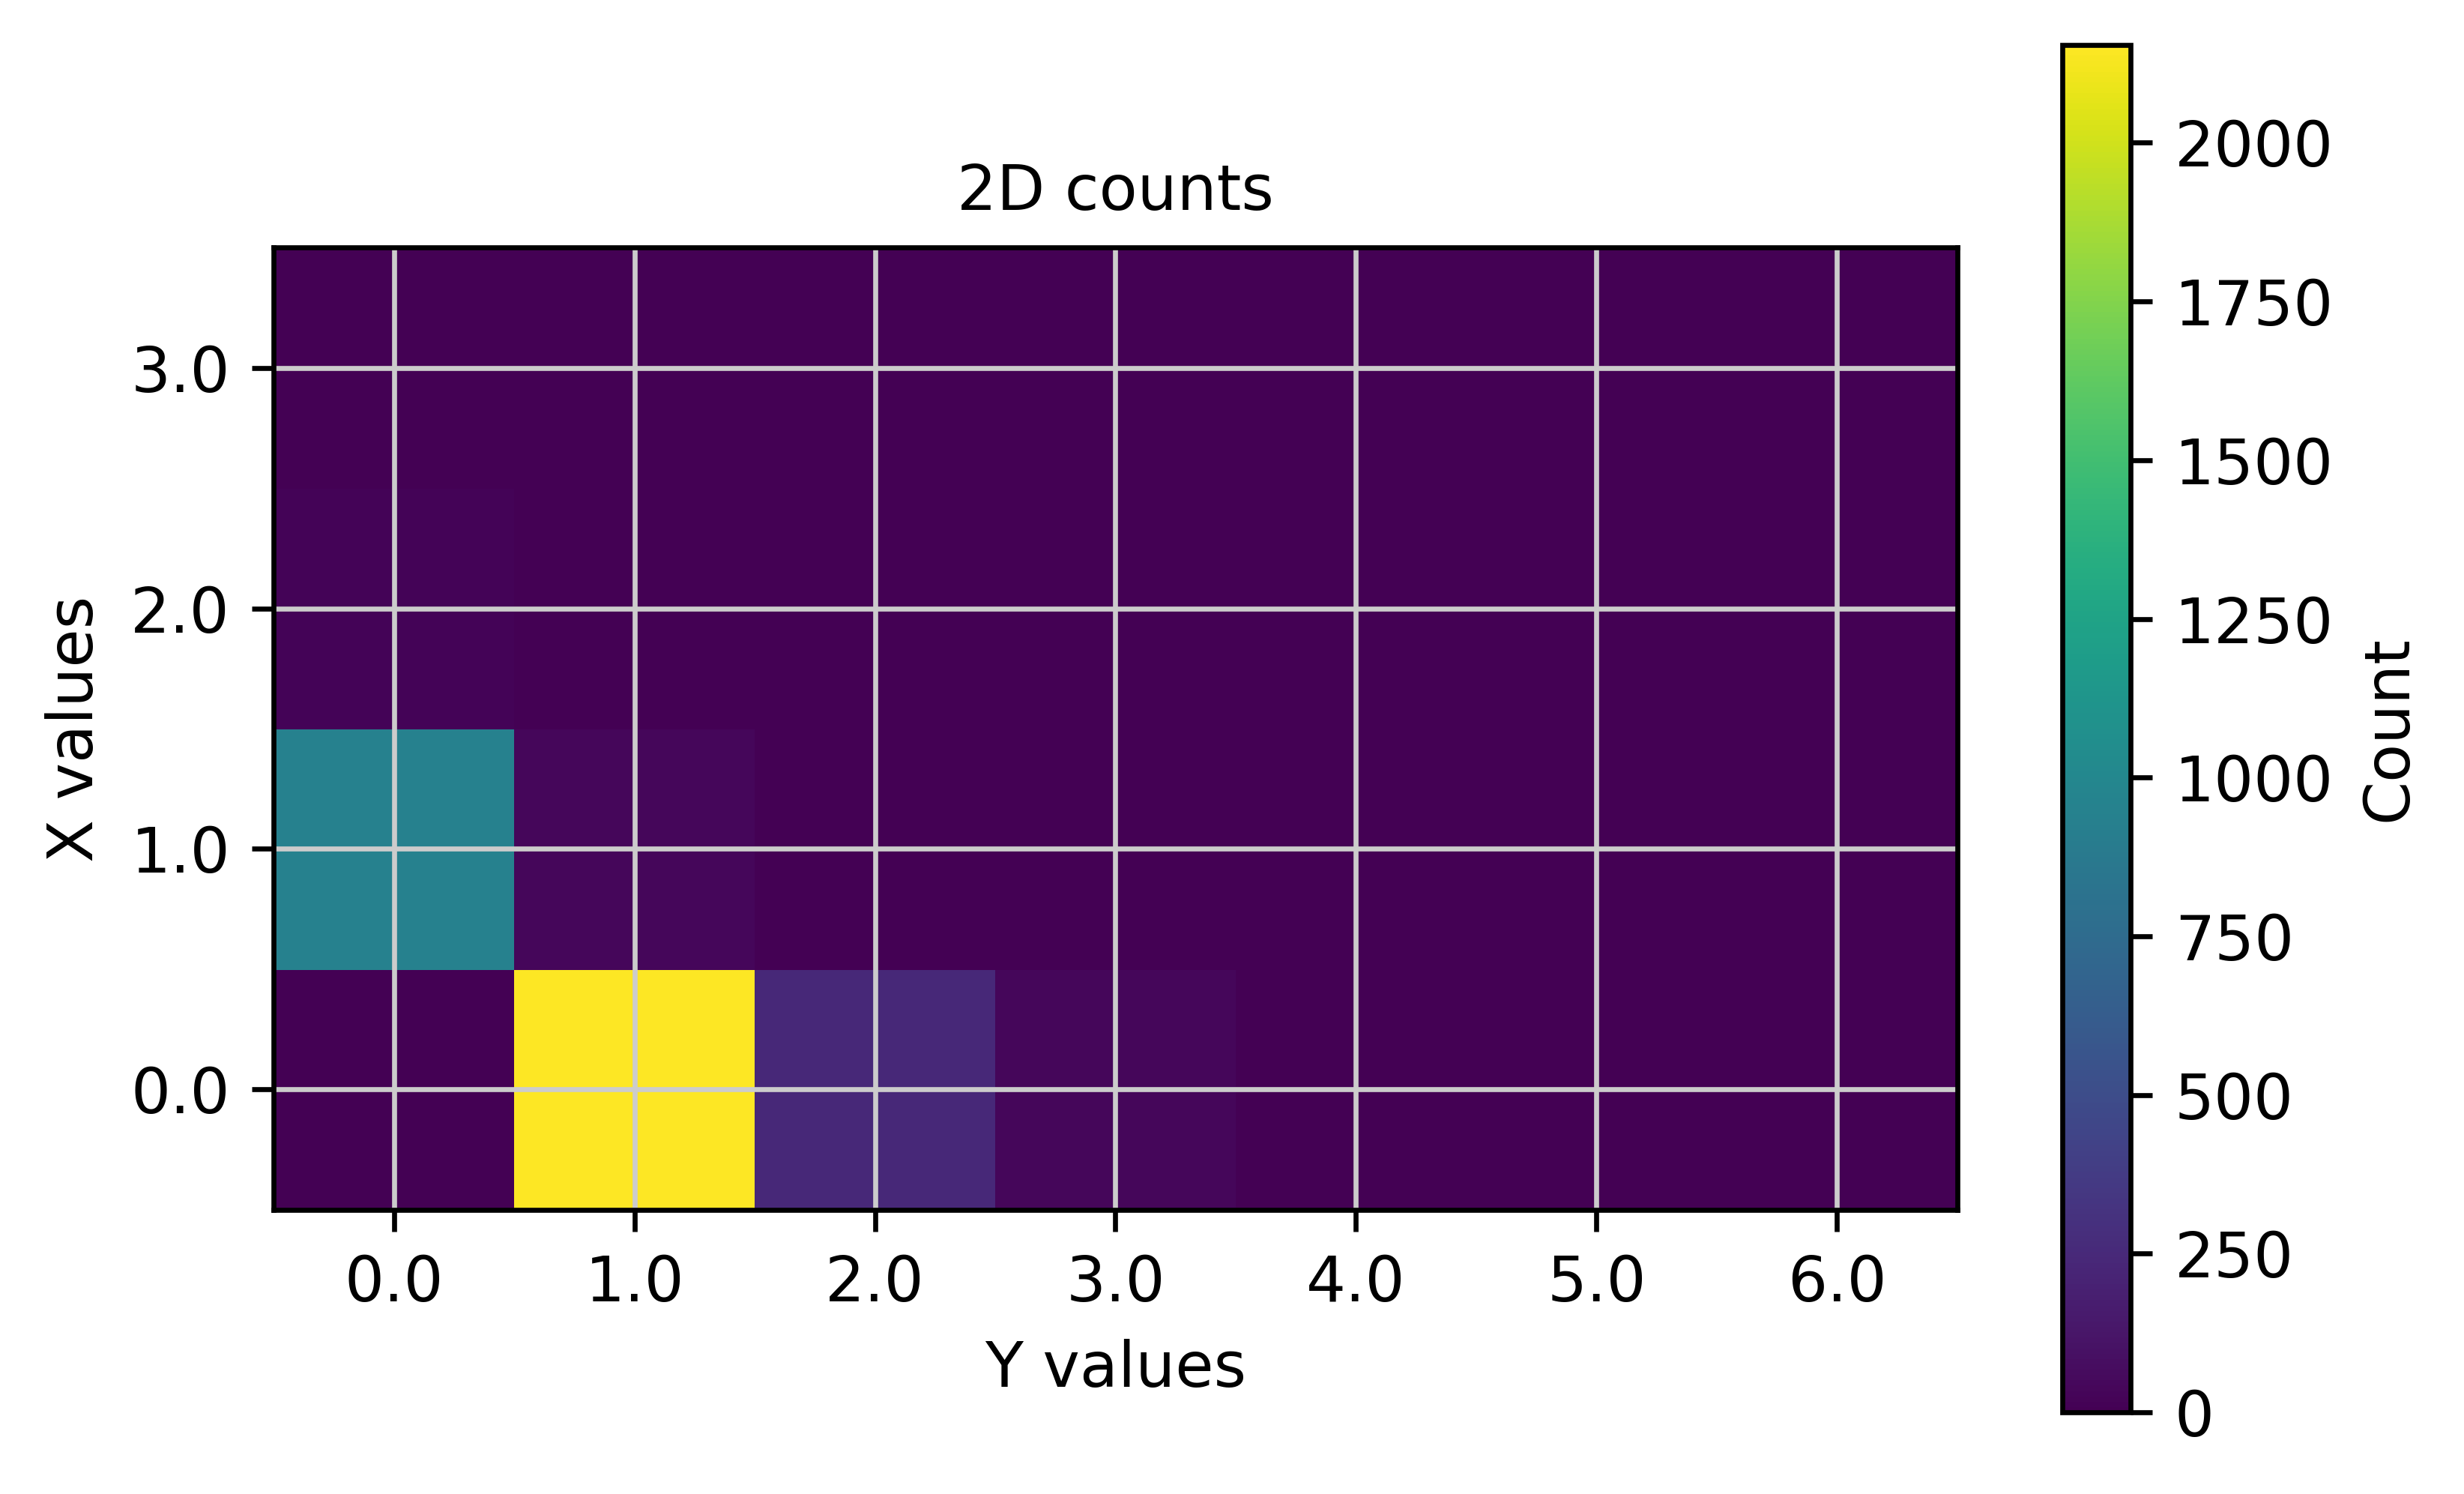

In [30]:
x = adata_sub_cell_pert[:, adata_sub_cell_pert.var_names.isin(['PDCD1'])].layers['counts'].toarray().flatten()
y = adata_sub_cell_pert[:, adata_sub_cell_pert.var_names.isin(['CTLA4'])].layers['counts'].toarray().flatten()

x_vals, y_vals = np.unique(x), np.unique(y)
count_matrix = np.zeros((len(x_vals), len(y_vals)), dtype=int)

for xi, yi in zip(x, y):
    count_matrix[np.where(x_vals == xi)[0][0],
                 np.where(y_vals == yi)[0][0]] += 1

plt.imshow(count_matrix, origin="lower")
plt.colorbar(label="Count")
plt.xticks(range(len(y_vals)), y_vals)
plt.yticks(range(len(x_vals)), x_vals)
plt.xlabel("Y values")
plt.ylabel("X values")
plt.title("2D counts")
plt.show()

In [33]:
A = adata_sub_cell_pert.obsm['neighborhood_emb']
B = adata_sub_cell_pert.obsm['neighborhood_emb_perturb_case1']

A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)

cos_sim = np.sum(A_norm * B_norm, axis=1)
print(np.mean(cos_sim))
print(np.min(cos_sim))

0.9999617
0.99911016


### 2.5.2 Perturbation Case 2

Knockout Perturbation:
- Cell & Neighborhood
    - CTLA4 (ENSG00000163599)
    - PDCD1 (ENSG00000188389)
    - KDR (ENSG00000128052)
    - FLT4 (ENSG00000037280)
    - PDGFRA (ENSG00000134853)
    - PDGFRB (ENSG00000113721)
    - KIT (ENSG00000157404)
    - CSF3R (ENSG00000119535)
    - FLT3 (ENSG00000122025)

In [ ]:
pert_genes = [
    'CTLA4',
    'PDCD1',
    'KDR',
    'FLT4',
    'PDGFRA',
    'PDGFRB',
    'KIT',
    'CSF3R',
    'FLT3']

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case2")

In [ ]:
cell_ids = list(perturbed_dataset['cell_id'])

In [ ]:
adata_pert = adata[adata.obs_names.isin(cell_ids)]

In [ ]:
A = adata_pert.obsm['cell_emb']
B = adata_pert.obsm['cell_emb_perturb_case2']

A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)

cos_sim = np.sum(A_norm * B_norm, axis=1)
print(np.mean(cos_sim))

In [ ]:
A = adata_pert.obsm['neighborhood_emb']
B = adata_pert.obsm['neighborhood_emb_perturb_case2']

A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)

cos_sim = np.sum(A_norm * B_norm, axis=1)
print(np.mean(cos_sim))

In [ ]:
cell_pert_indices = [0, 2, 4, 6, 8, 10, 12, 14]

filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[f"pert_flag_idx_{i}"] for i in cell_pert_indices)
)

In [ ]:
cell_pert_cell_ids = list(filtered_dataset['cell_id'])

In [ ]:
adata_sub_cell_pert = adata[adata.obs_names.isin(cell_pert_cell_ids)]

In [ ]:
A = adata_sub_cell_pert.obsm['cell_emb']
B = adata_sub_cell_pert.obsm['cell_emb_perturb_case2']

A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)

cos_sim = np.sum(A_norm * B_norm, axis=1)
print(np.mean(cos_sim))

In [ ]:
perturb_df

In [ ]:
thresh = 0.99
for i, gene in enumerate(pert_genes):
    cell_pert_indices = [i*2]
    
    filtered_dataset = perturbed_dataset.filter(
        lambda x: any(x[f"pert_flag_idx_{i}"] for i in cell_pert_indices)
    )
    
    cell_pert_cell_ids = list(filtered_dataset['cell_id'])
    
    adata_sub_cell_pert = adata[adata.obs_names.isin(cell_pert_cell_ids)]
    
    A = adata_sub_cell_pert.obsm['cell_emb']
    B = adata_sub_cell_pert.obsm['cell_emb_perturb_case2']
    
    A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
    B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)
    
    cos_sim = np.sum(A_norm * B_norm, axis=1)
    print(f"Gene: {gene}")
    print(f"Mean cosine similarity: {np.mean(cos_sim)}")
    print(f"Min cosine similarity: {np.min(cos_sim)}")
    print(f"Smaller than {thresh}: {int((cos_sim < thresh).sum())}/{cos_sim.shape[0]}")

In [ ]:
    - CTLA4 (ENSG00000163599)
    - PDCD1 (ENSG00000188389)
    - KDR (ENSG00000128052)
    - FLT4 (ENSG00000037280)
    - PDGFRA (ENSG00000134853)
    - PDGFRB (ENSG00000113721)
    - KIT (ENSG00000157404)
    - CSF3R (ENSG00000119535)
    - FLT3 (ENSG00000122025)

In [ ]:
x = adata[:, adata_sub_cell_pert.var_names.isin(['FLT3'])].layers['counts'].toarray().flatten()
values, counts = np.unique(x, return_counts=True)

plt.bar(values, counts)
plt.xlabel("Integer value")
plt.ylabel("Number of occurrences")
plt.title("Frequency of values")
plt.show()

In [ ]:
cell_ids = list(perturbed_dataset['cell_id'])

## 2.6 Decode Counts

In [ ]:
import anndata as ad
from app.count_decoder import apply_count_decoder
from app.count_decoder import _spot_level_metrics, _apply_metric_transform, _to_dense
import numpy as np

adata_path = "/nfs/team361/sb75/DATASETS/gold/cell-graph-tokenizer/kidney_perturbation/nemokidneyxeniumatlas_annotated_processed.h5ad"
checkpoint_path = "results/zinb_decoder.pt"  # or a folder with zinb_decoder.pt inside
emb_key = "cell_emb"
checkpoint_path = "results_neb/zinb_decoder.pt"  # or a folder with zinb_decoder.pt inside
emb_key="neighborhood_emb"

adata = ad.read_h5ad(adata_path)

adata = apply_count_decoder(
    adata,
    emb_key=emb_key,
    model_folder_path=checkpoint_path,  # can be folder or exact file
    decoded_counts_layer_key="decoded_counts",
    # optional overrides:
    # loss_type="nb_softplus",
    # device=0,
    # batch_size=1024,
)
 
preds = _to_dense(adata.layers["decoded_counts"])
target = _to_dense(adata.layers["counts"])
target = _to_dense(adata.layers["counts_neighborhood"])

# optional: same transform used in training metrics
preds = _apply_metric_transform(preds, "none")  # or "log1p"
target = _apply_metric_transform(target, "none")

spot_metrics = _spot_level_metrics(preds, target)
print(spot_metrics)

adata.write_h5ad("/path/to/output_with_decoded_counts.h5ad")

In [ ]:
adata = apply_count_decoder(
    adata,
    emb_key='neighborhood_emb',
    model_folder_path='/nfs/team361/mv10/nemo_v6/nichejepa/results_neb/zinb_decoder.pt',
    decoded_counts_layer_key='dec_counts_neighborhood')

In [ ]:
adata = apply_count_decoder(
    adata,
    emb_key='cell_emb',
    model_folder_path='/nfs/team361/mv10/nemo_v6/nichejepa/results/zinb_decoder.pt',
    decoded_counts_layer_key='dec_counts_cell'

In [ ]:
adata = apply_count_decoder(
    adata,
    emb_key='neighborhood_emb_perturb_case1',
    model_folder_path='/nfs/team361/mv10/nemo_v6/nichejepa/results_neb/zinb_decoder.pt',
    decoded_counts_layer_key='dec_counts_perturbed_neighborhood_case1'

In [ ]:
adata = apply_count_decoder(
    adata,
    emb_key='cell_emb_perturb_case1',
    model_folder_path='/nfs/team361/mv10/nemo_v6/nichejepa/results/zinb_decoder.pt',
    decoded_counts_layer_key='dec_counts_perturbed_cell_case1'

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

In [ ]:
diff testing dec_counts_neighborhood <-> dec_counts_perturbed_neighborhood

In [ ]:
# adata.obsm[emb_key] -> adata.layers[decoded_counts_layer_key]

In [ ]:
perturb_df = perturb_df.head(3)

In [ ]:
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    cell_gene_ids=cell_gene_ids,
    neighborhood_gene_ids=neighborhood_gene_ids,
    agg_excluded_tokens=agg_excluded_tokens,
    top_k=top_k,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers)

In [ ]:
adata.obsm['perturbed_cell_emb'] = perturbed_output_embed['cell_emb']
adata.obsm['perturbed_neighborhood_emb'] = perturbed_output_embed['neighborhood_emb']

In [ ]:
label = cell_type_key

# Neighborhood embedding UMAP
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='perturbed_neighborhood_emb',
                key_added='perturbed_neighborhood')
sc.tl.umap(adata,
           neighbors_key='perturbed_neighborhood',
           key_added='perturbed_neighborhood_umap')
adata.obsm['X_umap'] = adata.obsm['perturbed_neighborhood_umap']
sc.pl.umap(adata,
           neighbors_key='perturbed_neighborhood',
           color=label)

# Cell embedding UMAP
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='perturbed_cell_emb',
                key_added='perturbed_cell')
sc.tl.umap(adata,
           neighbors_key='perturbed_cell',
           key_added='perturbed_cell_umap')
adata.obsm['X_umap'] = adata.obsm['perturbed_cell_umap']
sc.pl.umap(adata,
           neighbors_key='perturbed_cell',
           color=label)